# 00 · EDA y preparación de datos

**Objetivo de negocio:** entender qué datos tiene Nile Prime y qué se puede (y no se puede)
hacer con ellos antes de abordar los cuatro retos: sentimiento de reseñas, recomendador
híbrido, predicción de abandono y mejora por refuerzo.

**Objetivo técnico:** auditar tipos, nulos, duplicados y distribuciones de los tres CSV;
cuantificar con rigor estadístico (IC de Wilson al 95 %, chi-cuadrado, V de Cramér) la señal
del abandono por edad y género; caracterizar popularidad y dispersión usuario-ítem; y fijar
las decisiones de preparación que heredan los retos. La limpieza vive en `src/data.py`; este
notebook solo la invoca.

**Nota sobre las cifras:** las cifras citadas en el texto corresponden a la **ejecución
completa** (`full`). Con `NP_FAST=1` varían (submuestreo) y valen las salidas de las celdas.

## Requisitos

- **Local:** Python ≥ 3.11 y `pip install -r requirements.txt` (o `python harness/init.py --install`, que crea el `.venv`).
- **Colab:** la celda de instalación de más abajo ejecuta `%pip install -q paquete==versión` **solo para lo que falte** (versión fijada). No se reinstalan `numpy`, `pandas`, `scikit-learn`, `matplotlib` ni `torch`: Colab ya los trae y cambiarlos obliga a reiniciar el entorno, lo que rompe «Ejecutar todo». Si no hay `data/raw`, la primera celda clona el repositorio público (o usa `NilePrime_AliGuerrero_codigo.zip` en `/content`).
- **Librerías de este notebook (versión de `requirements.txt`):** `pandas==2.3.3`, `numpy==2.3.5`, `matplotlib==3.10.6`, `seaborn==0.13.2`, `scipy==1.18.1`.

In [1]:
# Entorno: Colab o local y raíz del proyecto sin rutas absolutas (la instalación va en la celda siguiente).
REPO_URL = "https://github.com/aliguerreroj/nile-prime-ia.git"  # repositorio público con código y datos
ZIP_NAME = "NilePrime_AliGuerrero_codigo.zip"  # alternativa sin GitHub: subirlo a /content

import os
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
FAST = os.environ.get("NP_FAST") == "1"
SEED = 42

# Raíz = primera carpeta (cwd o sus padres) que contiene data/raw.
RAIZ = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "raw").is_dir()),
    None,
)
if RAIZ is None and EN_COLAB:
    # Colab: (a) zip en /content, (b) si no hay zip, git clone del repositorio público.
    import subprocess
    import zipfile

    _base = Path("/content")

    def _buscar_raiz():
        """Rutas directas primero; rglob solo como último recurso (sin recorrer /content/drive)."""
        for _d in (_base / "nile-prime-ia", _base / "NilePrime_AliGuerrero_codigo", _base):
            if (_d / "data" / "raw").is_dir():
                return _d
        for _sub in sorted(_base.iterdir()):
            if _sub.is_dir() and _sub.name not in ("drive", "sample_data"):
                for _raw in sorted(_sub.rglob("raw")):
                    if _raw.parent.name == "data" and _raw.is_dir():
                        return _raw.parent.parent
        return None

    for _z in sorted(_base.glob("NilePrime*codigo*.zip")) or sorted(_base.glob("*.zip")):
        with zipfile.ZipFile(_z) as _f:
            if any("data/raw/" in n for n in _f.namelist()):
                _f.extractall(_base)
                break
    RAIZ = _buscar_raiz()
    if RAIZ is None:
        try:
            _git = subprocess.run(["git", "clone", "--depth", "1", REPO_URL], cwd=_base,
                                  check=False, capture_output=True, text=True)
            _err = (_git.stderr or _git.stdout or "").strip().splitlines()
        except OSError as _e:
            _err = [str(_e)]
        RAIZ = _buscar_raiz()
        if RAIZ is None:
            raise RuntimeError(
                "No se pudo obtener el proyecto en Colab. Opción 1: comprueba la conexión a "
                "internet y vuelve a ejecutar (se clona " + REPO_URL + "). Opción 2: sube "
                + ZIP_NAME + " a /content y vuelve a ejecutar. Último error de git: "
                + (_err[-1] if _err else "sin salida")
            )
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra data/raw: ejecuta el notebook desde la carpeta del proyecto o una subcarpeta."
    )
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

In [2]:
# Instalación de dependencias (solo Colab, solo lo que falte; en local no instala nada).
# Colab ya trae todo lo demás; scipy se comprueba por si acaso.
import importlib.util

# paquete pip -> (módulo importable, versión fijada en requirements.txt)
_REQUISITOS = {"scipy": ("scipy", "1.18.1")}
_faltan = [f"{p}=={v}" for p, (m, v) in _REQUISITOS.items() if importlib.util.find_spec(m) is None]
if EN_COLAB and _faltan:
    for _spec in _faltan:
        # Equivalente a la magia:  %pip install -q scipy==1.18.1
        # (se usa run_line_magic porque jupytext no descomenta magias dentro de un bloque `if`).
        get_ipython().run_line_magic("pip", f"install -q {_spec}")  # noqa: F821
    print("Instalado:", ", ".join(_faltan))
else:
    print("Nada que instalar" + ("" if EN_COLAB else " (entorno local: usa requirements.txt)"))

Nada que instalar (entorno local: usa requirements.txt)


In [3]:
# Imports, semilla y configuración común.
import json
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import data, plots, stats

warnings.filterwarnings("ignore")
np.random.seed(SEED)
plots.set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
MODO = "fast" if FAST else "full"
print(f"Modo: {MODO} | SEED = {SEED} | Colab: {EN_COLAB}")

# Acumulador de cifras para reports/metrics/eda.json
M: dict = {"modo": MODO, "seed": SEED}

Modo: full | SEED = 42 | Colab: False


## 1. Carga y tipos de datos

**Qué:** cargar los tres datasets con los loaders de `src/data.py` y revisar dimensiones y
`dtype`. **Por qué:** los loaders encapsulan las correcciones verificadas (HTML en reseñas,
año erróneo de *Apollo 13*, nulos de `Certificate`), de modo que todos los notebooks parten
de la misma versión limpia. En `NP_FAST=1` las reseñas se submuestrean estratificadas y las
interacciones por usuario completo (se conserva la estructura usuario-ítem).

In [4]:
rev = data.load_reviews()
meta = data.load_metadata(titulos_unicos=True)
inter = data.load_interactions()

for nombre, df in [("reseñas", rev), ("metadatos", meta), ("interacciones", inter)]:
    print(f"{nombre}: {df.shape[0]:,} filas x {df.shape[1]} columnas")
    print(df.dtypes.astype(str).value_counts().to_dict())

print("\nColumnas de interacciones:", list(inter.columns))
print("¿Existe una columna de tiempo visto?:", any("time" in c.lower() or "tiempo" in c.lower()
                                                 for c in inter.columns))
M["filas"] = {"resenas": len(rev), "metadatos": len(meta), "interacciones": len(inter)}
M["tiene_columna_tiempo_visto"] = False
M["usuarios"] = int(inter["User_ID"].nunique())
M["titulos_en_interacciones"] = int(inter["Series_Title"].nunique())
M["titulos_sin_metadatos"] = int((~inter["Series_Title"].drop_duplicates().isin(
    meta["Series_Title"])).sum())
print(f"Usuarios: {M['usuarios']:,} | títulos: {M['titulos_en_interacciones']:,} | "
      f"títulos sin metadatos: {M['titulos_sin_metadatos']}")

reseñas: 50,000 filas x 2 columnas
{'object': 2}
metadatos: 999 filas x 17 columnas
{'object': 10, 'int64': 4, 'float64': 3}
interacciones: 100,624 filas x 4 columnas
{'object': 2, 'int64': 1, 'bool': 1}

Columnas de interacciones: ['User_ID', 'Series_Title', 'Watched_to_End', 'Age_Group']
¿Existe una columna de tiempo visto?: False
Usuarios: 10,000 | títulos: 999 | títulos sin metadatos: 0


**Hallazgos estructurales (verificados):**
- Las **reseñas** solo tienen `review` y `sentiment`: no hay título de película, por lo que
  **no pueden unirse** a metadatos ni a interacciones. El reto de sentimiento es un módulo
  independiente.
- Las **interacciones** son `User_ID, Series_Title, Watched_to_End, Age_Group`. **No existe
  la columna de tiempo visto** que menciona el enunciado: la variable de abandono solo puede
  derivarse de `Watched_to_End` (binaria), sin gradación de cuánto se vio.
- Los **metadatos** son una película por fila (`Drishyam` aparece con dos películas distintas,
  2013 y 2015; se usa `titulos_unicos=True` para tener clave única al unir con interacciones).

**Conclusión técnica:** la unión metadatos–interacciones es posible por título; reseñas queda
aislado y el abandono es una etiqueta binaria sin dimensión temporal.

**Implicación de negocio:** no podemos medir "cuánto" ve la gente, solo si termina o no, y las
reseñas no dicen de qué película hablan.

## 2. Valores nulos

**Qué:** comparar los nulos del CSV **crudo** con los del dataframe tras `load_metadata()`.
**Por qué:** el loader convierte los nulos de `Certificate` en la categoría `"Desconocido"`
(la ausencia de certificación es informativa), pero deja `Meta_score` y `Gross` como `NaN`:
imputarlos aquí, antes de una partición, filtraría información del conjunto de test. Se
imputarán dentro del pipeline de cada reto, ajustando solo con train.

             nulos_originales  nulos_tras_carga
Certificate          101.0000                 0
Gross                169.0000               168
Meta_score           157.0000               156
Nulos en interacciones: 0 | nulos en reseñas: 0


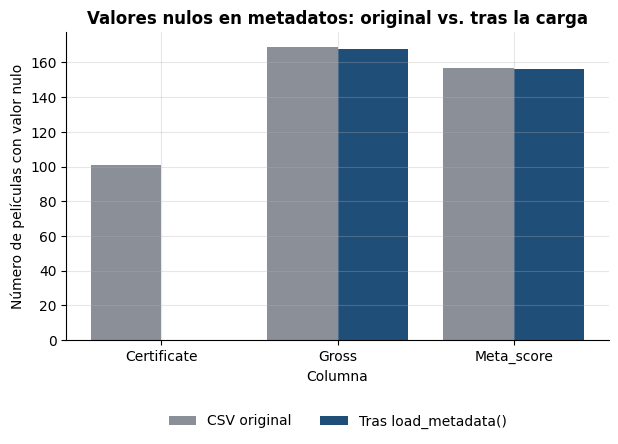

In [5]:
crudo = pd.read_csv(data.find_csv("Metadatos*.csv"))  # solo para contar nulos originales
nulos_ini = crudo.isna().sum()
nulos_fin = meta.isna().sum()
tabla_nulos = pd.DataFrame({"nulos_originales": nulos_ini, "nulos_tras_carga": nulos_fin})
tabla_nulos = tabla_nulos[(tabla_nulos > 0).any(axis=1)]
print(tabla_nulos.to_string())
print("Nulos en interacciones:", int(inter.isna().sum().sum()),
      "| nulos en reseñas:", int(rev.isna().sum().sum()))

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(tabla_nulos))
ax.bar(x - 0.2, tabla_nulos["nulos_originales"], 0.4, label="CSV original",
       color=plots.PALETA["neutro"])
ax.bar(x + 0.2, tabla_nulos["nulos_tras_carga"], 0.4, label="Tras load_metadata()",
       color=plots.PALETA["principal"])
ax.set_xticks(x, tabla_nulos.index)
ax.set_title("Valores nulos en metadatos: original vs. tras la carga")
ax.set_xlabel("Columna")
ax.set_ylabel("Número de películas con valor nulo")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
plots.save_fig(fig, "00_nulos_metadatos")
plt.show()

M["nulos_metadatos_originales"] = {k: int(v) for k, v in nulos_ini[nulos_ini > 0].items()}
M["nulos_metadatos_tras_carga"] = {k: int(v) for k, v in nulos_fin[nulos_fin > 0].items()}
M["nulos_interacciones"] = int(inter.isna().sum().sum())

**Conclusión técnica:** los nulos se concentran en `Certificate`, `Meta_score` y `Gross`
(tabla superior). La pequeña diferencia entre original y tras la carga (`Meta_score` 157→156,
`Gross` 169→168) **no es imputación**: `titulos_unicos=True` descarta una de las dos filas de
*Drishyam* y con ella desaparece un nulo de cada columna. `Certificate` queda resuelto como
categoría; `Meta_score` y `Gross` siguen siendo `NaN` y se imputarán (o se dejarán a un
modelo tolerante a NaN) dentro del pipeline, con indicador de ausencia. Interacciones y
reseñas no tienen nulos. Es probable que `Gross` falte de forma no aleatoria (películas
menos taquilleras), lo que sesga una imputación por media.

**Implicación de negocio:** los datos de cartelera son casi completos, pero la falta de
recaudación y de puntuación de crítica en algunas películas limita cuánto pueden aportar al
recomendador.

## 3. Duplicados

**Qué:** contar duplicados exactos en interacciones y por texto en reseñas (tras limpiar
HTML). **Por qué:** los duplicados por texto en reseñas provocan **fuga de datos** si una
misma reseña cae en train y test; los de interacciones inflan artificialmente un par
usuario–título.

In [6]:
rev_u = data.load_reviews(sin_duplicados=True)
inter_u = data.load_interactions(sin_duplicados=True)
dup_rev = len(rev) - len(rev_u)
dup_int = len(inter) - len(inter_u)
dup_meta = int(meta["Series_Title"].duplicated().sum())
dup_titulos_crudos = int(crudo["Series_Title"].duplicated().sum())
print(f"Reseñas duplicadas por texto (tras limpiar HTML): {dup_rev:,} (únicas: {len(rev_u):,})")
print(f"Interacciones duplicadas exactas: {dup_int}")
print(f"Títulos repetidos en metadatos crudos: {dup_titulos_crudos} "
      f"(tras titulos_unicos: {dup_meta})")
pares_rep = int(inter_u.duplicated(["User_ID", "Series_Title"]).sum())
print(f"Pares usuario–título repetidos tras quitar duplicados exactos: {pares_rep}")

M["duplicados"] = {
    "resenas_por_texto": int(dup_rev),
    "interacciones_exactas": int(dup_int),
    "titulos_repetidos_metadatos_crudos": dup_titulos_crudos,
    "pares_usuario_titulo_repetidos": pares_rep,
}

Reseñas duplicadas por texto (tras limpiar HTML): 422 (únicas: 49,578)
Interacciones duplicadas exactas: 1
Títulos repetidos en metadatos crudos: 1 (tras titulos_unicos: 0)
Pares usuario–título repetidos tras quitar duplicados exactos: 0


**Conclusión técnica:** hay 422 reseñas duplicadas por texto de 50.000 (0,84 %; se eliminan con
`sin_duplicados=True` **antes** del split en T03, comparando solo el texto, no la etiqueta),
un duplicado exacto en interacciones y un título repetido en metadatos (*Drishyam*) que se
resuelve con `titulos_unicos=True`. En modo `fast` las cifras de reseñas e interacciones son
menores por el submuestreo.

**Implicación de negocio:** el volumen de datos "sucios" es pequeño (<1 %), pero ignorarlo
haría que los modelos parecieran mejores de lo que son.

## 4. Distribuciones

**Qué:** balance de clases en reseñas, distribución de `Age_Group`, y resumen de las variables
numéricas de metadatos. **Por qué:** el balance determina las métricas válidas (accuracy vs.
PR-AUC); las distribuciones de metadatos señalan asimetrías (p. ej. `Gross`, `No_of_Votes`)
que afectan al preprocesado.

In [7]:
print("Sentimiento (reseñas):", rev["sentiment"].value_counts(normalize=True).round(4).to_dict())
print("Age_Group (interacciones):", inter["Age_Group"].value_counts(normalize=True)
      .round(4).to_dict())
num = meta[["Released_Year", "Runtime", "IMDB_Rating", "Meta_score", "No_of_Votes", "Gross"]]
resumen = num.describe(percentiles=[0.5]).T
resumen["asimetria"] = num.skew()
print(resumen[["count", "mean", "std", "min", "50%", "max", "asimetria"]].to_string())
len_rev = rev["review"].str.split().str.len()
print(f"Longitud de reseña (palabras): mediana {len_rev.median():.0f}, "
      f"p95 {len_rev.quantile(0.95):.0f}, máx {len_rev.max()}")

M["balance_resenas_positiva"] = float((rev["sentiment"] == rev["sentiment"].unique()[0]).mean())
M["longitud_resena_palabras"] = {"mediana": float(len_rev.median()),
                                 "p95": float(len_rev.quantile(0.95))}

Sentimiento (reseñas): {'positive': 0.5, 'negative': 0.5}
Age_Group (interacciones): {'adults': 0.3356, 'youth': 0.3355, 'seniors': 0.3289}
                 count            mean              std         min             50%              max  asimetria
Released_Year 999.0000      1,991.1992          23.2871  1,920.0000      1,999.0000       2,020.0000    -0.9390
Runtime       999.0000        122.8539          28.0832     45.0000        119.0000         321.0000     1.2121
IMDB_Rating   999.0000          7.9489           0.2754      7.6000          7.9000           9.3000     1.0207
Meta_score    843.0000         77.9715          12.3761     28.0000         79.0000         100.0000    -0.6052
No_of_Votes   999.0000    273,936.1251     327,446.2743 25,088.0000    138,741.0000   2,343,110.0000     2.2989
Gross         831.0000 68,034,750.8736 109,750,043.1922  1,305.0000 23,530,892.0000 936,662,225.0000     3.1301


Longitud de reseña (palabras): mediana 171, p95 585, máx 2459


**Conclusión técnica:** reseñas balanceadas por construcción (≈50/50 en ambos modos, el
submuestreo es estratificado); grupos de edad casi equilibrados; `No_of_Votes` y `Gross`
presentan asimetría positiva marcada (coeficiente de asimetría en la tabla), por lo que
conviene transformar con log o usar modelos de árboles. La longitud de reseña tiene cola
larga (p95 ≫ mediana), relevante para truncado en modelos de texto.

**Implicación de negocio:** las audiencias por edad están repartidas de forma similar, de
modo que ningún grupo de edad domina los resultados.

## 5. Abandono: tasa global y desbalance

**Qué:** tasa de `Watched_to_End == False` sobre las interacciones **sin el duplicado exacto**
(n = 100.623, frente a las 100.624 de la sección 1). **Por qué:** define
el problema del reto 3. Con una clase positiva minoritaria (~10 %), *accuracy* es engañosa
(predecir siempre "no abandona" ya da ~90 %); se usarán PR-AUC, recall/precisión a un umbral
justificado y un baseline que domine la clase mayoritaria.

In [8]:
inter_u = inter_u.assign(abandono=~inter_u["Watched_to_End"])
n_tot = len(inter_u)
n_ab = int(inter_u["abandono"].sum())
tasa = n_ab / n_tot
lo, hi = stats.wilson_ci(n_ab, n_tot)
print(f"Abandono global: {tasa:.2%}  (IC 95 % Wilson [{lo:.2%}, {hi:.2%}])  n = {n_tot:,}")
print(f"Accuracy del baseline 'nunca abandona': {1 - tasa:.2%} | prevalencia = {tasa:.2%}")
M["abandono_global"] = {"n": n_tot, "abandonos": n_ab, "tasa": float(tasa),
                        "ic95": [float(lo), float(hi)],
                        "accuracy_baseline_mayoritaria": float(1 - tasa)}

Abandono global: 10.25%  (IC 95 % Wilson [10.07%, 10.44%])  n = 100,623
Accuracy del baseline 'nunca abandona': 89.75% | prevalencia = 10.25%


**Conclusión técnica:** prevalencia de abandono ≈ 10 % (desbalance moderado ~9:1). Un
clasificador trivial alcanza ≈ 90 % de accuracy, por lo que esa métrica no discrimina; se
evaluará con PR-AUC (cuyo baseline aleatorio es la prevalencia), curvas PR y un umbral de
decisión basado en costes.

**Implicación de negocio:** "acertar" el 90 % no tiene mérito: lo que importa es detectar a
quien realmente se va, que es una minoría.

## 6. Abandono por grupo de edad

**Qué:** tasa por `Age_Group` con IC 95 % de Wilson y contraste chi-cuadrado de independencia
con tamaño del efecto (V de Cramér). **Por qué:** con n ≈ 10⁵ un p-valor minúsculo puede
coexistir con un efecto prácticamente nulo; V de Cramér (0 = independencia, 1 = asociación
perfecta) cuantifica la magnitud (convención: <0,1 despreciable). Se asume independencia entre
filas, aunque un mismo usuario aporta varias interacciones (dependencia intra-usuario que
estrecha en exceso los IC): es una limitación a tener en cuenta.

               n  eventos   tasa  ic_inf  ic_sup
Age_Group                                       
youth      33758     3660 0.1084  0.1051  0.1118
seniors    33092     3353 0.1013  0.0981  0.1046
adults     33773     3302 0.0978  0.0946  0.1010
chi2 = 21.56, gl = 2, p = 2.08e-05, V de Cramér = 0.0146


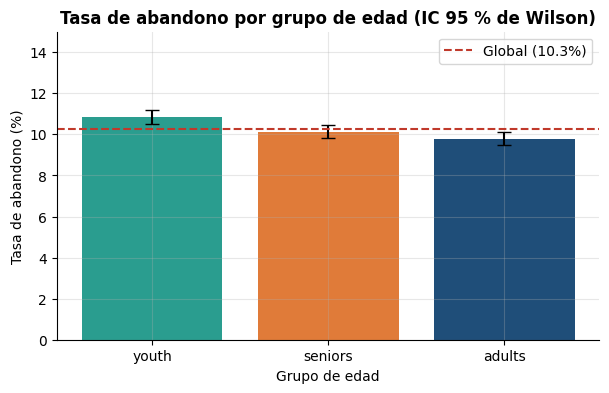

In [9]:
t_edad = stats.rate_table(inter_u, "Age_Group", "abandono").sort_values("tasa", ascending=False)
c_edad = stats.chi2_cramer(inter_u, "Age_Group", "abandono")
print(t_edad.to_string())
print(f"chi2 = {c_edad['chi2']:.2f}, gl = {c_edad['gl']}, p = {c_edad['p']:.2e}, "
      f"V de Cramér = {c_edad['cramer_v']:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
err = np.vstack([t_edad["tasa"] - t_edad["ic_inf"], t_edad["ic_sup"] - t_edad["tasa"]]) * 100
ax.bar(t_edad.index, t_edad["tasa"] * 100, yerr=err, capsize=5,
       color=[plots.GRUPOS_EDAD[g] for g in t_edad.index])
ax.axhline(tasa * 100, color=plots.PALETA["referencia"], ls="--", label=f"Global ({tasa:.1%})")
ax.set_title("Tasa de abandono por grupo de edad (IC 95 % de Wilson)")
ax.set_xlabel("Grupo de edad")
ax.set_ylabel("Tasa de abandono (%)")
ax.set_ylim(0, max(15, t_edad["ic_sup"].max() * 100 * 1.2))
ax.legend()
plots.save_fig(fig, "00_abandono_por_edad")
plt.show()

M["abandono_por_edad"] = {
    "tasas": {k: float(v) for k, v in t_edad["tasa"].items()},
    "ic95": {k: [float(a), float(b)] for k, a, b in zip(t_edad.index, t_edad["ic_inf"],
                                                         t_edad["ic_sup"], strict=True)},
    "chi2": c_edad["chi2"], "p": c_edad["p"], "gl": c_edad["gl"],
    "cramer_v": c_edad["cramer_v"],
}

**Conclusión técnica:** youth 10,84 %, seniors 10,13 %, adults 9,78 %. Con n≈10⁵, p≈2e-5
(chi² = 21,56, gl = 2) pero V≈0,015 (<0,1): asociación estadísticamente detectable y de
magnitud despreciable. La edad aporta **señal débil** y sola no predecirá el abandono.

**Implicación de negocio:** segmentar campañas de retención solo por edad tendría un
impacto marginal.

## 7. Abandono por género (multi-etiqueta)

**Qué:** unir interacciones con metadatos por título, separar `Genre` (", ") y hacer
`explode`: una interacción cuenta una vez por cada género de su película. **Por qué:** el
género es multi-etiqueta (1–3 por película). Advertencias metodológicas: (i) tras el
`explode` las observaciones **no son independientes** (la misma interacción aparece en varios
géneros), por lo que los IC y el chi-cuadrado son aproximados y optimistas; (ii) hay ~21
comparaciones, así que algún género extremo aparecerá por azar (**multiplicidad**); se
reporta el IC por género y se interpreta el rango, no se declara significancia individual.

Géneros: 21 | n mínimo por género: 1,770
Rango de abandono: 9.52% (Crime) a 11.40% (Western)
chi2 = 21.98, gl = 20, p = 3.41e-01, V de Cramér = 0.0093 (aproximado: observaciones repetidas)
Géneros cuyo IC 95 % excluye la tasa global (sin corregir): 2 de 21


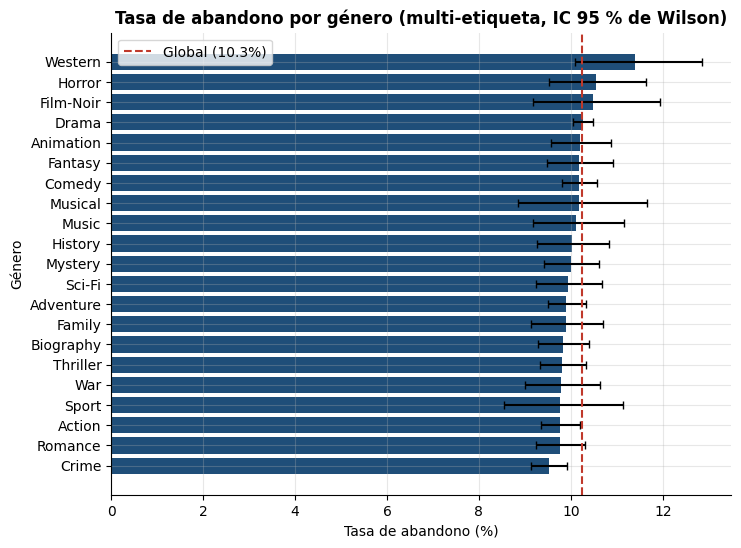

In [10]:
m_gen = meta[["Series_Title", "Genre"]].assign(genero=lambda d: d["Genre"].str.split(", "))
uni = inter_u.merge(m_gen[["Series_Title", "genero"]], on="Series_Title", how="inner")
assert len(uni) == len(inter_u), "Hay interacciones sin metadatos"
gen = uni.explode("genero")
t_gen = stats.rate_table(gen, "genero", "abandono").sort_values("tasa")
c_gen = stats.chi2_cramer(gen, "genero", "abandono")
print(f"Géneros: {len(t_gen)} | n mínimo por género: {int(t_gen['n'].min()):,}")
print(f"Rango de abandono: {t_gen['tasa'].min():.2%} ({t_gen['tasa'].idxmin()}) a "
      f"{t_gen['tasa'].max():.2%} ({t_gen['tasa'].idxmax()})")
print(f"chi2 = {c_gen['chi2']:.2f}, gl = {c_gen['gl']}, p = {c_gen['p']:.2e}, "
      f"V de Cramér = {c_gen['cramer_v']:.4f} (aproximado: observaciones repetidas)")
# ¿Algún IC excluye la tasa global? (sin corrección por multiplicidad)
fuera = t_gen[(t_gen["ic_inf"] > tasa) | (t_gen["ic_sup"] < tasa)]
print(f"Géneros cuyo IC 95 % excluye la tasa global (sin corregir): {len(fuera)} de {len(t_gen)}")

fig, ax = plt.subplots(figsize=(8, 6))
err = np.vstack([t_gen["tasa"] - t_gen["ic_inf"], t_gen["ic_sup"] - t_gen["tasa"]]) * 100
ax.barh(t_gen.index, t_gen["tasa"] * 100, xerr=err, capsize=3, color=plots.PALETA["principal"])
ax.axvline(tasa * 100, color=plots.PALETA["referencia"], ls="--", label=f"Global ({tasa:.1%})")
ax.set_title("Tasa de abandono por género (multi-etiqueta, IC 95 % de Wilson)")
ax.set_xlabel("Tasa de abandono (%)")
ax.set_ylabel("Género")
ax.legend()
plots.save_fig(fig, "00_abandono_por_genero")
plt.show()

M["abandono_por_genero"] = {
    "n_generos": int(len(t_gen)), "n_min": int(t_gen["n"].min()),
    "min": {"genero": t_gen["tasa"].idxmin(), "tasa": float(t_gen["tasa"].min())},
    "max": {"genero": t_gen["tasa"].idxmax(), "tasa": float(t_gen["tasa"].max())},
    "chi2": c_gen["chi2"], "p": c_gen["p"], "gl": c_gen["gl"], "cramer_v": c_gen["cramer_v"],
    "generos_ic_excluye_global_sin_corregir": int(len(fuera)),
    "nota": "Observaciones no independientes (explode multi-etiqueta) y 21 comparaciones.",
}

**Conclusión técnica:** el abandono va de 9,52 % (Crime) a 11,40 % (Western); chi² = 21,98,
gl = 20, p≈0,34, V≈0,009: no hay evidencia de asociación. Los géneros con IC que excluyen
la tasa global deben leerse con cautela por multiplicidad y dependencia entre filas. Género y edad dan **señal
débil**: el modelo de abandono no debe esperar un AUC alto basándose en ellas; la ganancia,
si la hay, vendrá de características de usuario (historial) y de ítem.

**Implicación de negocio:** el género no discrimina el abandono con los datos disponibles;
no conviene retirar ni promocionar títulos por su género.

## 8. Popularidad de títulos y dispersión usuario-ítem

**Qué:** distribución de interacciones por título y por usuario, y densidad de la matriz
usuario-ítem. **Por qué:** una cola larga de popularidad sesga a un recomendador hacia el
*top-N*; la densidad y la actividad por usuario fijan el riesgo de **arranque en frío** y la
viabilidad del filtrado colaborativo.

Por título: min 71, mediana 100, p90 114, max 221
Por usuario: min 1, mediana 10, p90 14, max 24
Usuarios 10,000 x títulos 999 | densidad = 1.007% | el 10 % de títulos más vistos concentra el 11.9% de las interacciones
Usuarios con ≤ 2 interacciones: 25
Rango intercuartílico por título: 93–107
Top de títulos por nº de interacciones: {'Drishyam': 221, 'The Hobbit: The Desolation of Smaug': 133, 'The Circus': 132, 'Under sandet': 132, 'Barton Fink': 131}
Desviación típica por título: 11.0 (sin el máximo: 10.4) | esperada bajo reparto uniforme: 10.0
Máximo (Drishyam) = 221 vs. segundo = 133; ¿título compartido por varias películas en el CSV crudo?: True


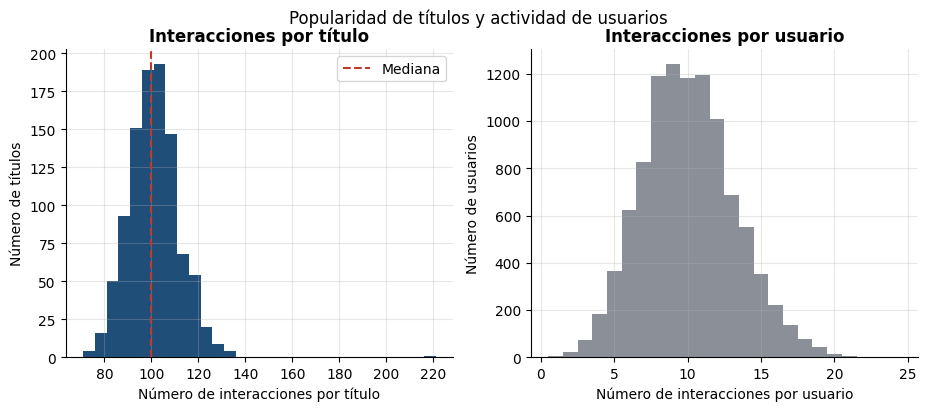

In [11]:
por_titulo = inter_u.groupby("Series_Title").size()
por_usuario = inter_u.groupby("User_ID").size()
n_u, n_i = inter_u["User_ID"].nunique(), inter_u["Series_Title"].nunique()
densidad = len(inter_u.drop_duplicates(["User_ID", "Series_Title"])) / (n_u * n_i)
pt = por_titulo.quantile([0.5, 0.9]).to_dict()
print(f"Por título: min {por_titulo.min()}, mediana {pt[0.5]:.0f}, p90 {pt[0.9]:.0f}, "
      f"max {por_titulo.max()}")
pu = por_usuario.quantile([0.5, 0.9]).to_dict()
print(f"Por usuario: min {por_usuario.min()}, mediana {pu[0.5]:.0f}, p90 {pu[0.9]:.0f}, "
      f"max {por_usuario.max()}")
top10 = por_titulo.nlargest(max(1, int(0.1 * n_i))).sum() / por_titulo.sum()
print(f"Usuarios {n_u:,} x títulos {n_i:,} | densidad = {densidad:.3%} | "
      f"el 10 % de títulos más vistos concentra el {top10:.1%} de las interacciones")
print("Usuarios con ≤ 2 interacciones:", int((por_usuario <= 2).sum()))
q1, q3 = por_titulo.quantile([0.25, 0.75])
print(f"Rango intercuartílico por título: {q1:.0f}–{q3:.0f}")
top_titulos = por_titulo.nlargest(5)
print("Top de títulos por nº de interacciones:", top_titulos.to_dict())
# Dispersión observada vs. la esperada si cada interacción cayera en un título al azar
# (multinomial uniforme: sd = sqrt(n·p·(1-p)), p = 1/n_i).
sd_obs = float(por_titulo.std())
sd_obs_sin_max = float(por_titulo.drop(top_titulos.index[0]).std())
sd_esp = float(np.sqrt(len(inter_u) * (1 / n_i) * (1 - 1 / n_i)))
print(f"Desviación típica por título: {sd_obs:.1f} (sin el máximo: {sd_obs_sin_max:.1f}) "
      f"| esperada bajo reparto uniforme: {sd_esp:.1f}")
t1, t2 = top_titulos.iloc[0], top_titulos.iloc[1]
colision = bool(crudo["Series_Title"].eq(top_titulos.index[0]).sum() > 1)
print(f"Máximo ({top_titulos.index[0]}) = {t1} vs. segundo = {t2}; "
      f"¿título compartido por varias películas en el CSV crudo?: {colision}")

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].hist(por_titulo, bins=30, color=plots.PALETA["principal"])
axs[0].axvline(por_titulo.median(), color=plots.PALETA["referencia"], ls="--", label="Mediana")
axs[0].set_title("Interacciones por título")
axs[0].set_xlabel("Número de interacciones por título")
axs[0].set_ylabel("Número de títulos")
axs[0].legend()
axs[1].hist(por_usuario, bins=np.arange(0.5, por_usuario.max() + 1.5),
            color=plots.PALETA["neutro"])
axs[1].set_title("Interacciones por usuario")
axs[1].set_xlabel("Número de interacciones por usuario")
axs[1].set_ylabel("Número de usuarios")
fig.suptitle("Popularidad de títulos y actividad de usuarios")
plots.save_fig(fig, "00_popularidad_titulos")
plt.show()

M["popularidad"] = {
    "por_titulo": {"min": int(por_titulo.min()), "mediana": float(pt[0.5]),
                   "p90": float(pt[0.9]), "max": int(por_titulo.max()),
                   "q1": float(q1), "q3": float(q3),
                   "segundo_max": int(t2), "titulo_max": str(top_titulos.index[0]),
                   "max_es_colision_de_titulo": colision},
    "por_usuario": {"min": int(por_usuario.min()), "mediana": float(pu[0.5]),
                    "p90": float(pu[0.9]), "max": int(por_usuario.max())},
    "usuarios": int(n_u), "titulos": int(n_i), "densidad_matriz": float(densidad),
    "concentracion_top10pct_titulos": float(top10),
    "sd_por_titulo": sd_obs, "sd_por_titulo_sin_maximo": sd_obs_sin_max,
    "sd_esperada_multinomial_uniforme": sd_esp,
}

**Conclusión técnica:** la popularidad por título es **casi uniforme**, sin cola larga:
mínimo 71, mediana 100, p90 114 (rango intercuartílico 93–107), ≈ 100 ± 10 interacciones por
título, y el 10 % de títulos más vistos acumula el 11,9 % de las interacciones frente al
10 % de un reparto uniforme. La desviación típica observada (11,0; 10,4 sin *Drishyam*) es
prácticamente la esperada bajo un reparto multinomial uniforme (√(n·p·(1−p)) ≈ 10,0): la
variabilidad entre títulos es casi toda ruido de muestreo. La única excepción es
`Drishyam` (221 interacciones; el siguiente título tiene 133), un **artefacto de colisión de
título**: dos películas distintas (2013 y 2015) comparten nombre y las interacciones solo
llevan el título, así que se suman bajo una clave y el join (`titulos_unicos=True`) las
asigna a la fila retenida (2015). No se puede desambiguar con la clave de interacciones;
afecta a género y atributos de esas ~221 filas y es una limitación a documentar en los
retos 2 y 3. Al no haber sesgo de popularidad, el *baseline* de popularidad discriminará
poco. La matriz usuario-ítem es **muy dispersa** (densidad ≈ 1 %): ~10 interacciones por
usuario sobre ~10³ ítems, lo que dificulta el filtrado colaborativo y exige un componente
basado en contenido (metadatos) y manejo explícito de usuarios nuevos (*cold start*). En
modo `fast` hay menos usuarios (10 %) y la densidad por usuario se mantiene.

**Implicación de negocio:** al haber pocos datos por usuario, para recomendar bien hay que
apoyarse también en las características de las películas, no solo en lo que vio cada persona.

## 9. Estructura de preferencias

**Qué:** comprobar si las elecciones de título de los usuarios contienen alguna señal
aprovechable: (a) ¿depende el título elegido del grupo de edad? (chi-cuadrado de
independencia sobre la tabla 3 × 999, con V de Cramér bruta y corregida); (b) ¿son
coherentes los títulos de un mismo usuario (comparten género o director) más de lo que se
esperaría al azar? **Por qué:** un recomendador (retos 2 y 4) solo puede aprender si el
histórico tiene estructura usuario–ítem; si la elección fuera independiente de las
covariables y entre títulos del mismo usuario, cualquier modelo rendiría como el azar en
*leave-one-out*.

**Diseño.** (a) Con n ≈ 10⁵ repartidas en 2.997 celdas hay ≈ 34 observaciones por celda: la
V de Cramér **bruta está sesgada al alza** (bajo H0, E[χ²] ≈ gl, luego V ≈ √(gl / (n·(k−1)))
≈ 0,1 aunque no exista asociación). Se contrasta con ese valor esperado y con la corrección
de Bergsma (2013). (b) Estadístico: proporción de pares de títulos del mismo usuario que
comparten ≥ 1 género (multi-etiqueta) o director. Nulo: **prueba de permutación** que
baraja la columna `Series_Title` entre interacciones (conserva el nº de interacciones por
usuario y la popularidad global), con réplicas suficientes para un p-valor empírico e IC del
baseline. Se usan **todos los usuarios**; el coste es de pocos segundos (pares vectorizados
en `src/stats.py`). Se usan `titulos_unicos=True` y `sin_duplicados=True`: *Drishyam* queda
con los atributos de la fila de 2015 (colisión documentada en la sección 8).

Tabla 3 x 999 | n = 100,623 | obs. por celda ≈ 34
chi2 = 1928.8, gl = 1996, p = 0.857 (E[chi2 | H0] ≈ gl = 1996)
V de Cramér bruta = 0.0979 | esperada bajo H0 = 0.0996 | corregida (Bergsma) = 0.0000
Máx. % de vistas de un solo grupo de edad en un título: 55.6% (mediana 37.7%; uniforme = 33.3%)
               n  anio_medio  anio_sd  rating_medio  rating_sd  anio_ic95  rating_ic95
Age_Group                                                                             
adults     33773  1,991.3550  23.2210        7.9490     0.2740     0.2480       0.0030
seniors    33092  1,991.1550  23.4290        7.9490     0.2760     0.2520       0.0030
youth      33758  1,991.2930  23.2390        7.9450     0.2730     0.2480       0.0030


Mismo género: observado 65.924% | barajado 65.944% [IC 95 % 65.811%, 66.067%] | p (2 colas) = 0.746
Mismo director: observado 0.238% | barajado 0.237% [IC 95 % 0.222%, 0.251%] | p (2 colas) = 0.915
Usuarios: 10,000 | pares: 505,732 | réplicas: 200 | tiempo (permutaciones): 2.4 s


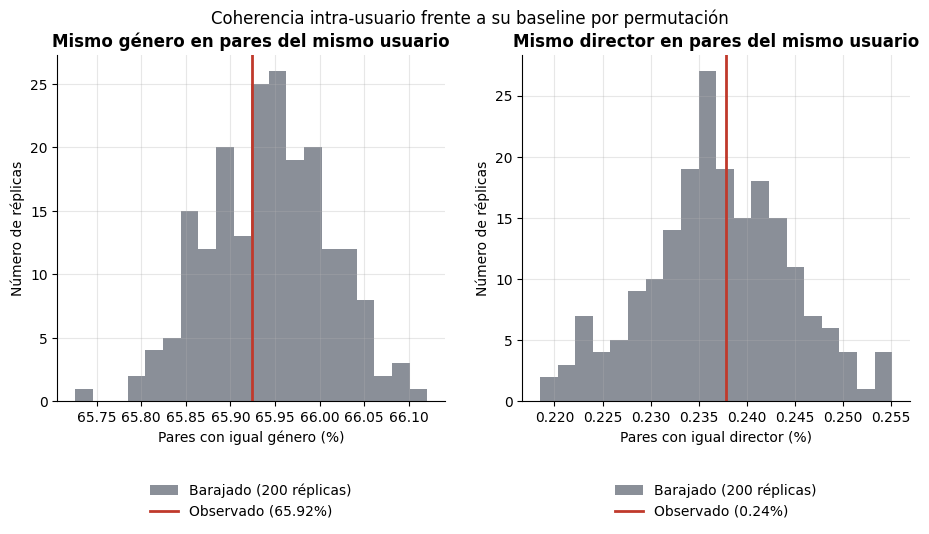

HitRate@10 esperado por azar en leave-one-out ≈ 10/999 = 1.00%


In [12]:
N_PERM = 30 if FAST else 200
inter_p = inter_u[["User_ID", "Series_Title", "Age_Group"]]

# (a) Edad x título
c_et = stats.chi2_cramer(inter_p, "Age_Group", "Series_Title")
filas_t, cols_t = inter_p["Age_Group"].nunique(), inter_p["Series_Title"].nunique()
v_esp = stats.cramer_v_esperada_h0(c_et["gl"], c_et["n"], min(filas_t, cols_t) - 1)
v_cor = stats.cramer_v_corregida(c_et["chi2"], c_et["n"], filas_t, cols_t)
print(f"Tabla {filas_t} x {cols_t} | n = {c_et['n']:,} | obs. por celda ≈ "
      f"{c_et['n'] / (filas_t * cols_t):.0f}")
print(f"chi2 = {c_et['chi2']:.1f}, gl = {c_et['gl']}, p = {c_et['p']:.3f} "
      f"(E[chi2 | H0] ≈ gl = {c_et['gl']})")
print(f"V de Cramér bruta = {c_et['cramer_v']:.4f} | esperada bajo H0 = {v_esp:.4f} | "
      f"corregida (Bergsma) = {v_cor:.4f}")

ct = pd.crosstab(inter_p["Series_Title"], inter_p["Age_Group"])
pct_max = ct.div(ct.sum(axis=1), axis=0).max(axis=1)
print(f"Máx. % de vistas de un solo grupo de edad en un título: {pct_max.max():.1%} "
      f"(mediana {pct_max.median():.1%}; uniforme = {1 / filas_t:.1%})")

attr = inter_p.merge(meta[["Series_Title", "Released_Year", "IMDB_Rating"]], on="Series_Title")
res_g = attr.groupby("Age_Group").agg(
    n=("Series_Title", "size"),
    anio_medio=("Released_Year", "mean"), anio_sd=("Released_Year", "std"),
    rating_medio=("IMDB_Rating", "mean"), rating_sd=("IMDB_Rating", "std"),
)
res_g["anio_ic95"] = 1.96 * res_g["anio_sd"] / np.sqrt(res_g["n"])
res_g["rating_ic95"] = 1.96 * res_g["rating_sd"] / np.sqrt(res_g["n"])
print(res_g.round(3).to_string())

# (b) Coherencia intra-usuario con prueba de permutación
cod_t = pd.Categorical(inter_p["Series_Title"], categories=meta["Series_Title"]).codes
gen_mh = meta["Genre"].str.get_dummies(", ").to_numpy().astype(np.int32)
sim_gen = (gen_mh @ gen_mh.T) > 0
cod_dir = pd.factorize(meta["Director"])[0]
sim_dir = cod_dir[:, None] == cod_dir[None, :]
usuarios_np = inter_p["User_ID"].to_numpy()

t0 = time.perf_counter()
coh_gen = stats.coherencia_permutacion(cod_t, usuarios_np, sim_gen, N_PERM, SEED)
coh_dir = stats.coherencia_permutacion(cod_t, usuarios_np, sim_dir, N_PERM, SEED)
seg = time.perf_counter() - t0
for nombre, c in [("género", coh_gen), ("director", coh_dir)]:
    print(f"Mismo {nombre}: observado {c['observado']:.3%} | barajado {c['nulo_media']:.3%} "
          f"[IC 95 % {c['nulo_ic95'][0]:.3%}, {c['nulo_ic95'][1]:.3%}] | "
          f"p (2 colas) = {c['p_dos_colas']:.3f}")
print(f"Usuarios: {inter_p['User_ID'].nunique():,} | pares: {coh_gen['n_pares']:,} | "
      f"réplicas: {N_PERM} | tiempo (permutaciones): {seg:.1f} s")

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (nombre, c) in zip(axs, [("género", coh_gen), ("director", coh_dir)], strict=True):
    ax.hist(c["nulo"] * 100, bins=20, color=plots.PALETA["neutro"],
            label=f"Barajado ({N_PERM} réplicas)")
    ax.axvline(c["observado"] * 100, color=plots.PALETA["referencia"], lw=2,
               label=f"Observado ({c['observado']:.2%})")
    ax.set_title(f"Mismo {nombre} en pares del mismo usuario")
    ax.set_xlabel(f"Pares con igual {nombre} (%)")
    ax.set_ylabel("Número de réplicas")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
fig.suptitle("Coherencia intra-usuario frente a su baseline por permutación")
plots.save_fig(fig, "00_estructura_preferencias")
plt.show()

hit_azar = 10 / cols_t
print(f"HitRate@10 esperado por azar en leave-one-out ≈ 10/{cols_t} = {hit_azar:.2%}")


def _sin_nulo(c: dict) -> dict:
    """Resultado de la permutación sin el array de réplicas (para el JSON)."""
    return {k: v for k, v in c.items() if k != "nulo"}


M["estructura_preferencias"] = {
    "edad_x_titulo": {
        "chi2": c_et["chi2"], "gl": c_et["gl"], "p": c_et["p"], "n": c_et["n"],
        "cramer_v_bruta": c_et["cramer_v"], "cramer_v_esperada_h0": v_esp,
        "cramer_v_corregida_bergsma": v_cor,
        "max_pct_un_grupo_por_titulo": float(pct_max.max()),
        "mediana_pct_max_por_titulo": float(pct_max.median()),
    },
    "media_por_grupo_edad": {
        g: {"anio_medio": float(r["anio_medio"]), "anio_ic95": float(r["anio_ic95"]),
            "rating_medio": float(r["rating_medio"]), "rating_ic95": float(r["rating_ic95"]),
            "n": int(r["n"])}
        for g, r in res_g.iterrows()
    },
    "coherencia_genero": _sin_nulo(coh_gen),
    "coherencia_director": _sin_nulo(coh_dir),
    "n_usuarios": int(inter_p["User_ID"].nunique()),
    "n_replicas_permutacion": int(N_PERM),
    "hitrate10_azar": float(hit_azar),
}

**Conclusión técnica:** **estas pruebas no detectan señal de preferencia en el histórico.**
(a) La elección de
título es independiente de la edad: χ² ≈ gl (p ≈ 0,86). La V bruta ≈ 0,098 no es un efecto,
es el sesgo de una tabla dispersa: coincide con la V esperada bajo H0 (≈ 0,100) y la V
corregida es 0. Ningún título supera el 56 % de vistas de un solo grupo de edad (uniforme =
33 %; con ≈ 100 vistas por título y 2.997 celdas, la probabilidad de un máximo así bajo H0
es ≈ 0,04: marginal, por lo que la conclusión se apoya en el χ² global) y el año
medio (≈ 1991) y el rating medio (≈ 7,95) son indistinguibles entre grupos (IC 95 %
solapados). (b) Los pares de títulos de un mismo usuario comparten género (≈ 66 %) y director
(≈ 0,24 %) con la misma frecuencia que los títulos barajados entre usuarios; el valor
observado cae dentro del IC del baseline (p empírico no significativo en ambos casos).
**Consecuencia:** no se observa estructura que el filtrado colaborativo pueda aprender y, en
*leave-one-out* sobre ≈ 10³ títulos, se espera que cualquier recomendador rinda ≈ azar:
HitRate@10 ≈ K/N ≈ 10/999 ≈ 1 % (valor teórico, no medido aquí; se mide en el reto 2). Los
resultados de los retos 2 y 4 deben interpretarse
contra ese techo, y una mejora aparente sobre el azar exige IC y prueba de significancia.

**Limitaciones:** (i) ausencia de evidencia no es evidencia de ausencia: con ≈ 5·10⁵ pares
y sd del baseline ≈ 0,07 pp la prueba de género detectaría desviaciones de ≈ 0,14 pp, pero
no efectos menores ni estructura de orden superior; (ii) el género es multi-etiqueta y
"comparte ≥ 1 género" es un criterio laxo (≈ 66 % por azar), poco sensible; (iii) la
colisión de *Drishyam* asigna a sus ~221 interacciones los atributos de una sola película;
(iv) el nulo por permutación supone intercambiabilidad de las interacciones entre usuarios
y excluye de la comparación los pares barajados con un título repetido (que de otro modo
inflarían la coherencia del baseline, sobre todo en director).

**Implicación de negocio:** este histórico no muestra gustos que aprender, así que no cabe
esperar que un recomendador demuestre mejoras sobre el azar con él ni conviene prometerlas.

## 10. Preparación: decisiones que heredan los retos

**Qué:** consolidar las decisiones de datos y guardar las cifras en `reports/metrics/eda.json`.
**Por qué:** una única fuente de verdad evita que cada reto reimplemente (o contradiga) la
limpieza.

| Decisión | Dónde se aplica | Motivo |
|---|---|---|
| `load_reviews(sin_duplicados=True)` antes del split | Reto 1 | Evitar fuga por duplicados |
| Reseñas = módulo independiente | Reto 1 | No hay título: no se une con nada |
| `load_metadata(titulos_unicos=True)` | Retos 2 y 3 | Clave única en el join (*Drishyam*) |
| `load_interactions(sin_duplicados=True)` | Retos 2 y 3 | Quitar el duplicado exacto |
| `Meta_score`/`Gross` con NaN, sin imputar aquí | Pipelines | Imputar solo con train |
| Partición **por usuario** (`GroupKFold`) | Reto 3 | Evitar fuga intra-usuario |
| PR-AUC, umbral por coste, no accuracy | Reto 3 | Desbalance ~10 % |
| Sin tiempo visto: etiqueta binaria | Retos 3 y 4 | La columna no existe |
| Techo de azar (leave-one-out, HitRate@10 ≈ 1 %) | Retos 2 y 4 | Sin estructura de preferencias |
| Comparar con azar/popularidad, con IC y prueba | Retos 2 y 4 | Mejoras pequeñas = ruido |
| Buscar señal en historial/ítem, no en edad/género | Reto 3 | Edad y género: V despreciable |

**Conclusión técnica:** las decisiones anteriores son vinculantes para T03–T06. Las señales
de edad y género sobre el abandono son débiles y la sección 9 muestra que la elección de
título no tiene estructura de preferencias. Consecuencias: **reto 2** (recomendador) y
**reto 4** (refuerzo) se evaluarán contra un techo de azar de ≈ 1 % de HitRate@10 en
*leave-one-out*, con IC y significancia frente al azar y a la popularidad (casi uniforme),
sin asumir que un modelo colaborativo aprende algo; **reto 3** (abandono) deberá buscar
señal en el historial del usuario y en las características del título, y se espera un
techo modesto.

**Implicación de negocio:** los datos permiten construir las soluciones, con la expectativa
realista de que el recomendador no superará al azar de forma clara y la predicción de
abandono tendrá un techo modesto.

In [13]:
ruta_json = RAIZ / "reports" / "metrics" / "eda.json"
ruta_json.parent.mkdir(parents=True, exist_ok=True)
ruta_json.write_text(json.dumps(M, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Métricas guardadas en reports/metrics/eda.json (modo = {M['modo']})")

Métricas guardadas en reports/metrics/eda.json (modo = full)
